# 02 - Modeling: LightGBM + XGBoost ensemble
Feature engineering -> 5-fold Stratified CV -> ensemble -> `submission.csv`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, lightgbm as lgb, xgboost as xgb, warnings
from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings('ignore')
D=Path('../data'); OUT=Path('../outputs/figures'); OUT.mkdir(exist_ok=True)
SEED=42; K=5
train=pd.read_csv(D/'train.csv'); test=pd.read_csv(D/'test.csv')

## Feature engineering

In [2]:
def prep(tr, te):
    tr=tr.copy(); te=te.copy(); tr['_is_tr']=1; te['_is_tr']=0
    df=pd.concat([tr,te],ignore_index=True).rename(columns={'duration_in min/ms':'duration'})
    df['dur_was_min']=(df.duration<100).astype(int)
    df['duration_ms']=np.where(df.duration<100, df.duration*60000, df.duration)
    for c in ['Popularity','key','instrumentalness']: df[c+'_na']=df[c].isna().astype(int)
    df['artist']=df['Artist Name'].fillna('NA')
    df['artist_freq']=df.groupby('artist')['Id'].transform('count')
    df['track_len']=df['Track Name'].fillna('').str.len()
    df['track_feat']=df['Track Name'].fillna('').str.contains('feat|with',case=False).astype(int)
    df['energy_dance']=df.energy*df.danceability
    df['loud_energy']=df.loudness/(df.energy+1e-3)
    df['acoustic_energy']=df.acousticness-df.energy
    return df
BASE=['Popularity','danceability','energy','key','loudness','mode','speechiness','acousticness','instrumentalness','liveness','valence','tempo','duration_ms','time_signature']
FE=BASE+['dur_was_min','Popularity_na','key_na','instrumentalness_na','artist_freq','track_len','track_feat','energy_dance','loud_energy','acoustic_energy']
df=prep(train,test); X=df[df._is_tr==1].reset_index(drop=True); XT=df[df._is_tr==0].reset_index(drop=True)
y=X.Class.astype(int).values; NC=len(np.unique(y)); print(X.shape, XT.shape, NC)

(14396, 31) (3600, 31) 11


In [3]:
def cv_lgb(feats):
    oof=np.zeros((len(X),NC)); pt=np.zeros((len(XT),NC))
    for a,b in StratifiedKFold(K,shuffle=True,random_state=SEED).split(X,y):
        m=lgb.LGBMClassifier(n_estimators=3000,learning_rate=0.03,num_leaves=31,subsample=0.8,subsample_freq=1,colsample_bytree=0.7,verbose=-1,random_state=SEED)
        m.fit(X.loc[a,feats],y[a],eval_set=[(X.loc[b,feats],y[b])],callbacks=[lgb.early_stopping(100,verbose=False)])
        oof[b]=m.predict_proba(X.loc[b,feats]); pt+=m.predict_proba(XT[feats])/K
    return oof,pt,m
def score(name,oof):
    p=oof.argmax(1); print(f'{name:28s} acc={accuracy_score(y,p):.4f}  macroF1={f1_score(y,p,average="macro"):.4f}')
oof_base,_,_=cv_lgb(BASE); score('LGBM raw features',oof_base)
oof_lgb,pt_lgb,last=cv_lgb(FE); score('LGBM + feature engineering',oof_lgb)

LGBM raw features            acc=0.4985  macroF1=0.4660
LGBM + feature engineering   acc=0.5731  macroF1=0.6184


In [4]:
def cv_xgb(feats):
    oof=np.zeros((len(X),NC)); pt=np.zeros((len(XT),NC))
    for a,b in StratifiedKFold(K,shuffle=True,random_state=SEED).split(X,y):
        m=xgb.XGBClassifier(n_estimators=3000,learning_rate=0.03,max_depth=6,subsample=0.8,colsample_bytree=0.7,early_stopping_rounds=100,eval_metric='mlogloss',random_state=SEED,n_jobs=-1)
        m.fit(X.loc[a,feats],y[a],eval_set=[(X.loc[b,feats],y[b])],verbose=False)
        oof[b]=m.predict_proba(X.loc[b,feats]); pt+=m.predict_proba(XT[feats])/K
    return oof,pt
oof_xgb,pt_xgb=cv_xgb(FE); score('XGB + feature engineering',oof_xgb)
oof_ens=(oof_lgb+oof_xgb)/2; pt_ens=(pt_lgb+pt_xgb)/2; score('Ensemble LGBM+XGB',oof_ens)

XGB + feature engineering    acc=0.5750  macroF1=0.6166
Ensemble LGBM+XGB            acc=0.5766  macroF1=0.6208


,Model,CV Accuracy,CV Macro-F1
0,LGBM raw,0.4985,0.4660
1,LGBM + FE,0.5731,0.6184
2,XGB + FE,0.5750,0.6166
3,Ensemble,0.5766,0.6208


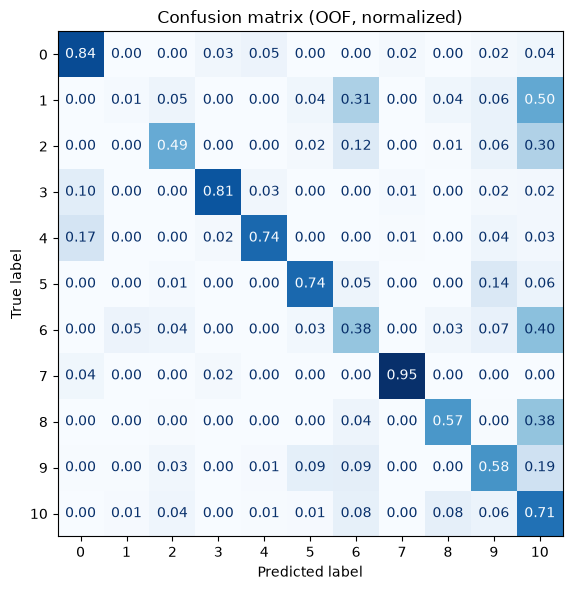

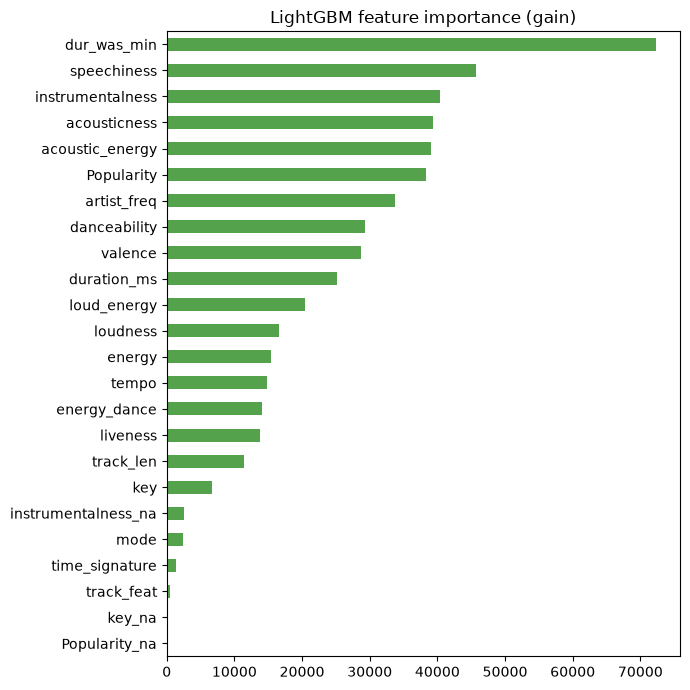

In [5]:
rows=[]
for n,o in [('LGBM raw',oof_base),('LGBM + FE',oof_lgb),('XGB + FE',oof_xgb),('Ensemble',oof_ens)]:
    p=o.argmax(1); rows.append((n,accuracy_score(y,p),f1_score(y,p,average='macro')))
res=pd.DataFrame(rows,columns=['Model','CV Accuracy','CV Macro-F1']).round(4); res.to_csv(OUT.parent/'results_cv.csv',index=False); display(res)
fig,ax=plt.subplots(figsize=(7,6)); ConfusionMatrixDisplay(confusion_matrix(y,oof_ens.argmax(1),normalize='true'),display_labels=range(NC)).plot(ax=ax,cmap='Blues',values_format='.2f',colorbar=False)
ax.set_title('Confusion matrix (OOF, normalized)'); plt.tight_layout(); plt.savefig(OUT/'confusion_matrix.png',dpi=150); plt.show()
imp=pd.Series(last.booster_.feature_importance('gain'),index=FE).sort_values()
imp.plot(kind='barh',figsize=(7,7),color='#54A24B',title='LightGBM feature importance (gain)'); plt.tight_layout(); plt.savefig(OUT/'feature_importance.png',dpi=150); plt.show()

In [6]:
from datetime import date
SUB=OUT.parent/'submissions'; SUB.mkdir(exist_ok=True)
cv=accuracy_score(y,oof_ens.argmax(1))
sub=pd.DataFrame({'Id':test['Id'],'Class':pt_ens.argmax(1)})
sub.to_csv(SUB/f'sub_{date.today():%Y%m%d}_ensemble_cv{cv:.4f}.csv',index=False)
print(sub.shape); print(sub.Class.value_counts().sort_index().to_dict()); sub.head()

(3600, 2)
{0: 139, 1: 33, 2: 224, 3: 75, 4: 85, 5: 279, 6: 474, 7: 104, 8: 314, 9: 472, 10: 1401}


,Id,Class
0,14397,6
1,14398,6
2,14399,9
3,14400,10
4,14401,5
